In [15]:

import pandas as pd
import numpy as np
import sys

from pathlib import Path

# Xác định thư mục gốc
ROOT = Path.cwd()

if not (ROOT / "src").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

from src.train_model import (
    SOURCE_COLUMNS,
    MODEL_FEATURES,
    prepare_data,
    build_origin_examples
)

# Đọc những cột cần thiết
raw = pd.read_parquet(
    ROOT / "data/processed/features.parquet",
    columns=SOURCE_COLUMNS
)

# Chuẩn bị dữ liệu
data = prepare_data(raw)
del raw

print("Shape:", data.shape)
print("First date:", data["date"].min())
print("Last date:", data["date"].max())

display(data.head())


Shape: (3000888, 8)
First date: 2013-01-01 00:00:00
Last date: 2017-08-15 00:00:00


,date,store_nbr,family,sales,sales_lag_7,sales_lag_28,sales_rolling_mean_7,family_code
0,2013-01-01,1,AUTOMOTIVE,0.0,NaN,NaN,NaN,0
1,2013-01-01,37,CELEBRATION,0.0,NaN,NaN,NaN,6
2,2013-01-01,37,BREAD/BAKERY,0.0,NaN,NaN,NaN,5
3,2013-01-01,37,BOOKS,0.0,NaN,NaN,NaN,4
4,2013-01-01,37,BEVERAGES,0.0,NaN,NaN,NaN,3


In [16]:

# Cấu hình thử nghiệm
HORIZON = 7
TRAIN_ORIGINS = 12
VAL_ORIGINS = 3
TEST_ORIGINS = 3

last_date = data["date"].max()

# Các thời điểm đánh giá cuối
test_cutoffs = [
    last_date - pd.Timedelta(days=HORIZON * i)
    for i in range(TEST_ORIGINS, 0, -1)
]

# Các thời điểm Validation, nằm trước Test
validation_cutoffs = [
    test_cutoffs[0] - pd.Timedelta(days=HORIZON * i)
    for i in range(VAL_ORIGINS, 0, -1)
]

# Các thời điểm Training, nằm trước Validation
training_cutoffs = [
    validation_cutoffs[0] - pd.Timedelta(days=HORIZON * i)
    for i in range(TRAIN_ORIGINS, 0, -1)
]

print("Training:", training_cutoffs)
print("Validation:", validation_cutoffs)
print("Test:", test_cutoffs)


Training: [Timestamp('2017-04-11 00:00:00'), Timestamp('2017-04-18 00:00:00'), Timestamp('2017-04-25 00:00:00'), Timestamp('2017-05-02 00:00:00'), Timestamp('2017-05-09 00:00:00'), Timestamp('2017-05-16 00:00:00'), Timestamp('2017-05-23 00:00:00'), Timestamp('2017-05-30 00:00:00'), Timestamp('2017-06-06 00:00:00'), Timestamp('2017-06-13 00:00:00'), Timestamp('2017-06-20 00:00:00'), Timestamp('2017-06-27 00:00:00')]
Validation: [Timestamp('2017-07-04 00:00:00'), Timestamp('2017-07-11 00:00:00'), Timestamp('2017-07-18 00:00:00')]
Test: [Timestamp('2017-07-25 00:00:00'), Timestamp('2017-08-01 00:00:00'), Timestamp('2017-08-08 00:00:00')]


In [17]:

# Tạo dữ liệu Training
train_parts = []

for cutoff in training_cutoffs:

    examples = build_origin_examples(
        data,
        cutoff=cutoff,
        horizon=HORIZON
    )

    train_parts.append(examples)

train_samples = pd.concat(
    train_parts,
    ignore_index=True
)

# Tạo dữ liệu Validation
val_parts = []

for cutoff in validation_cutoffs:

    examples = build_origin_examples(
        data,
        cutoff=cutoff,
        horizon=HORIZON
    )

    val_parts.append(examples)

val_samples = pd.concat(
    val_parts,
    ignore_index=True
)

print("Training shape:", train_samples.shape)
print("Validation shape:", val_samples.shape)

display(train_samples[[
    "cutoff",
    "date",
    "store_nbr",
    "family_code",
    "sales",
    "baseline_reference",
    "cutoff_sales",
    "horizon_step"
]].head())


Training shape: (149688, 17)
Validation shape: (37422, 17)


,cutoff,date,store_nbr,family_code,sales,baseline_reference,cutoff_sales,horizon_step
0,2017-04-11,2017-04-12,36,29,50.459999,78.0,68.059998,1
1,2017-04-11,2017-04-12,37,4,0.000000,0.0,0.000000,1
2,2017-04-11,2017-04-12,37,3,2630.000000,3315.0,2390.000000,1
3,2017-04-11,2017-04-12,37,2,0.000000,6.0,5.000000,1
4,2017-04-11,2017-04-12,37,1,0.000000,0.0,0.000000,1


In [18]:

print("Last training target:", train_samples["date"].max())
print("First validation cutoff:", validation_cutoffs[0])

print("Last validation target:", val_samples["date"].max())
print("First test cutoff:", test_cutoffs[0])

assert train_samples["date"].max() <= validation_cutoffs[0]
assert val_samples["date"].max() <= test_cutoffs[0]

print("Chronological split: PASSED")


Last training target: 2017-07-04 00:00:00
First validation cutoff: 2017-07-04 00:00:00
Last validation target: 2017-07-25 00:00:00
First test cutoff: 2017-07-25 00:00:00
Chronological split: PASSED


In [19]:

import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingRegressor
from src.train_model import MODEL_FEATURES
from src.baseline import calculate_metrics

# Bỏ các feature thiếu toàn bộ dữ liệu huấn luyện
active_features = [
    col for col in MODEL_FEATURES
    if train_samples[col].notna().any()
]

categorical_features = [
    col for col in ["store_nbr", "family_code"]
    if col in active_features
]

# Dữ liệu đầu vào
X_train = train_samples[active_features]
X_val = val_samples[active_features]

# Nhãn mục tiêu
y_train = np.log1p(train_samples["sales"])

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("Features:", active_features)


X_train: (149688, 13)
X_val: (37422, 13)
y_train: (149688,)
Features: ['store_nbr', 'family_code', 'year', 'month', 'day_of_month', 'day_of_week', 'is_weekend', 'horizon_step', 'baseline_reference', 'cutoff_sales', 'cutoff_lag_7', 'cutoff_lag_28', 'cutoff_rolling_mean_7']


In [20]:

configs = [
    {"max_iter": 50, "learning_rate": 0.06},
    {"max_iter": 100, "learning_rate": 0.06}
]

results = []

for config in configs:

    model = HistGradientBoostingRegressor(
        **config,
        loss="squared_error",
        max_leaf_nodes=25,
        min_samples_leaf=40,
        l2_regularization=2.0,
        categorical_features=categorical_features,
        random_state=42
    )

    # Huấn luyện mô hình
    model.fit(X_train, y_train)

    # Dự báo tập Training
    train_log_pred = model.predict(X_train)
    train_pred = np.expm1(
        np.clip(train_log_pred, 0, 25)
    )

    # Dự báo tập Validation
    val_log_pred = model.predict(X_val)
    val_pred = np.expm1(
        np.clip(val_log_pred, 0, 25)
    )

    # Đánh giá Training
    train_eval = train_samples[["sales"]].copy()
    train_eval["prediction"] = train_pred
    train_metrics = calculate_metrics(train_eval)

    # Đánh giá Validation
    val_eval = val_samples[["sales"]].copy()
    val_eval["prediction"] = val_pred
    val_metrics = calculate_metrics(val_eval)

    results.append({
        **config,
        "train_mae": train_metrics["mae"],
        "val_mae": val_metrics["mae"],
        "val_rmsle": val_metrics["rmsle"]
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,max_iter,learning_rate,train_mae,val_mae,val_rmsle
0,50,0.06,120.2202,101.7049,0.4232
1,100,0.06,74.3673,62.7139,0.3987


In [21]:

best_row = results_df.loc[
    results_df["val_mae"].idxmin()
]

print("Best max_iter:", int(best_row["max_iter"]))
print("Best learning_rate:", best_row["learning_rate"])
print("Validation MAE:", round(best_row["val_mae"], 4))
print("Validation RMSLE:", round(best_row["val_rmsle"], 4))


Best max_iter: 100
Best learning_rate: 0.06
Validation MAE: 62.7139
Validation RMSLE: 0.3987


In [22]:

best_model = HistGradientBoostingRegressor(
    max_iter=int(best_row["max_iter"]),
    learning_rate=float(best_row["learning_rate"]),
    loss="squared_error",
    max_leaf_nodes=25,
    min_samples_leaf=40,
    l2_regularization=2.0,
    categorical_features=categorical_features,
    random_state=42
)

best_model.fit(X_train, y_train)

print("Best model trained successfully!")


Best model trained successfully!


In [23]:

# Dự báo toàn bộ dữ liệu Validation
log_predictions = best_model.predict(X_val)

predictions = np.expm1(
    np.clip(log_predictions, 0, 25)
)

# Tạo bảng so sánh với thực tế
val_results = val_samples[
    ["cutoff", "date", "store_nbr", "family_code", "sales"]
].copy()

val_results["prediction"] = predictions

display(val_results.head(10))


,cutoff,date,store_nbr,family_code,sales,prediction
0,2017-07-04,2017-07-05,36,29,27.000000,43.350965
1,2017-07-04,2017-07-05,37,4,0.000000,0.054551
2,2017-07-04,2017-07-05,37,3,3005.000000,3072.450235
3,2017-07-04,2017-07-05,37,2,6.000000,4.626938
4,2017-07-04,2017-07-05,37,1,0.000000,0.054551
5,2017-07-04,2017-07-05,37,0,3.000000,4.638134
6,2017-07-04,2017-07-05,36,32,0.000000,0.941620
7,2017-07-04,2017-07-05,37,5,552.270020,592.259536
8,2017-07-04,2017-07-05,36,31,0.000000,0.200245
9,2017-07-04,2017-07-05,36,30,1086.698975,1117.893305


In [24]:

metrics_by_cutoff = []

for cutoff, group in val_results.groupby("cutoff"):

    metrics = calculate_metrics(group)

    metrics_by_cutoff.append({
        "cutoff": str(pd.Timestamp(cutoff).date()),
        "mae": metrics["mae"],
        "rmsle": metrics["rmsle"],
        "coverage": metrics["coverage"]
    })

cutoff_results = pd.DataFrame(metrics_by_cutoff)

display(cutoff_results.round(4))


,cutoff,mae,rmsle,coverage
0,2017-07-04,63.9169,0.3954,1.0
1,2017-07-11,64.1064,0.4000,1.0
2,2017-07-18,60.1182,0.4008,1.0


In [25]:

# Tạo bản sao để không thay đổi bảng gốc
error_df = val_results.copy()

# Tính sai số tuyệt đối của từng bản ghi
error_df["abs_error"] = (
    error_df["sales"] - error_df["prediction"]
).abs()

display(error_df[
    ["date", "family_code", "sales",
     "prediction", "abs_error"]
].head(10))


,date,family_code,sales,prediction,abs_error
0,2017-07-05,29,27.000000,43.350965,16.350965
1,2017-07-05,4,0.000000,0.054551,0.054551
2,2017-07-05,3,3005.000000,3072.450235,67.450235
3,2017-07-05,2,6.000000,4.626938,1.373062
4,2017-07-05,1,0.000000,0.054551,0.054551
5,2017-07-05,0,3.000000,4.638134,1.638134
6,2017-07-05,32,0.000000,0.941620,0.941620
7,2017-07-05,5,552.270020,592.259536,39.989516
8,2017-07-05,31,0.000000,0.200245,0.200245
9,2017-07-05,30,1086.698975,1117.893305,31.194330


In [26]:

family_errors = (
    error_df.groupby("family_code")
    .agg(
        sample_count=("abs_error", "size"),
        mae=("abs_error", "mean"),
        average_sales=("sales", "mean")
    )
    .sort_values("mae", ascending=False)
)

display(family_errors.head(10).round(2))


,sample_count,mae,average_sales
family_code,,,
3,1134,520.41,3574.409912
12,1134,507.93,4423.149902
30,1134,250.46,2351.689941
7,1134,245.00,1246.959961
8,1134,81.30,870.809998
5,1134,56.84,538.460022
24,1134,56.63,375.950012
28,1134,50.14,391.730011
25,1134,48.53,295.709991


In [27]:

# Tạo bảng ánh xạ mã và tên nhóm sản phẩm
family_lookup = data[
    ["family_code", "family"]
].drop_duplicates()

# Kết hợp tên sản phẩm vào bảng Error Analysis
family_report = family_errors.reset_index().merge(
    family_lookup,
    on="family_code",
    how="left",
    validate="many_to_one"
)

# Tính tỷ lệ MAE so với doanh số trung bình
family_report["mae_to_sales_pct"] = (
    family_report["mae"]
    / family_report["average_sales"].replace(0, np.nan)
) * 100

# Hiển thị kết quả
display(
    family_report[
        [
            "family",
            "sample_count",
            "mae",
            "average_sales",
            "mae_to_sales_pct"
        ]
    ].head(10).round(2)
)


,family,sample_count,mae,average_sales,mae_to_sales_pct
0,BEVERAGES,1134,520.41,3574.409912,14.56
1,GROCERY I,1134,507.93,4423.149902,11.48
2,PRODUCE,1134,250.46,2351.689941,10.65
3,CLEANING,1134,245.00,1246.959961,19.65
4,DAIRY,1134,81.30,870.809998,9.34
5,BREAD/BAKERY,1134,56.84,538.460022,10.56
6,MEATS,1134,56.63,375.950012,15.06
7,POULTRY,1134,50.14,391.730011,12.80
8,PERSONAL CARE,1134,48.53,295.709991,16.41
9,HOME CARE,1134,45.81,315.109985,14.54


In [28]:

# Tính sai số có dấu
error_df["signed_error"] = (
    error_df["prediction"] - error_df["sales"]
)

# Phân tích bias theo nhóm sản phẩm
bias_report = (
    error_df.groupby("family_code")
    .agg(
        mean_bias=("signed_error", "mean"),
        overprediction_rate_pct=(
            "signed_error",
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

# Ghép tên nhóm sản phẩm
bias_report = bias_report.merge(
    family_lookup,
    on="family_code",
    how="left",
    validate="many_to_one"
)

# Sắp xếp theo độ lớn bias
bias_report["abs_bias"] = bias_report["mean_bias"].abs()

bias_report = bias_report.sort_values(
    "abs_bias", ascending=False
)

display(
    bias_report[
        ["family", "mean_bias", "overprediction_rate_pct"]
    ].head(10).round(2)
)


,family,mean_bias,overprediction_rate_pct
3,BEVERAGES,-234.48,41.36
12,GROCERY I,-110.36,48.24
30,PRODUCE,-93.56,47.80
24,MEATS,-16.35,48.68
28,POULTRY,-15.01,45.94
22,"LIQUOR,WINE,BEER",-12.10,44.18
18,HOME CARE,-8.11,50.18
10,EGGS,-7.49,49.38
8,DAIRY,-5.45,50.26
13,GROCERY II,-4.70,47.00


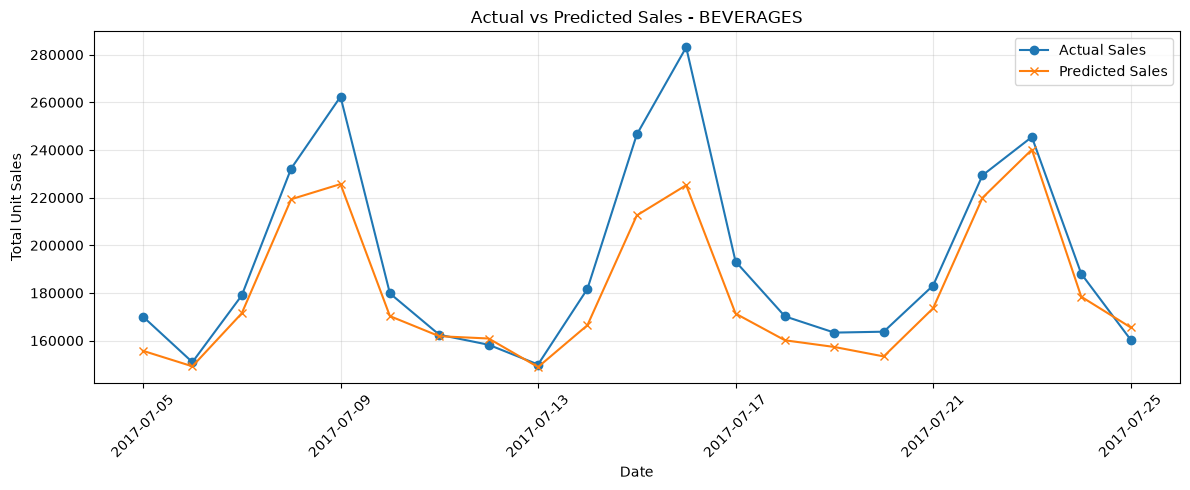

In [29]:

import pandas as pd
import matplotlib.pyplot as plt

# Chọn nhóm sản phẩm cần phân tích
selected_family = "BEVERAGES"

# Ghép tên nhóm sản phẩm vào kết quả dự báo
plot_df = val_results.merge(
    family_lookup,
    on="family_code",
    how="left",
    validate="many_to_one"
)

# Lọc dữ liệu BEVERAGES
beverages = plot_df[
    plot_df["family"] == selected_family
]

# Tính tổng doanh số theo ngày trên tất cả cửa hàng
daily_comparison = (
    beverages.groupby("date")[["sales", "prediction"]]
    .sum()
    .sort_index()
)

# Vẽ biểu đồ
plt.figure(figsize=(12, 5))

plt.plot(
    daily_comparison.index,
    daily_comparison["sales"],
    label="Actual Sales",
    marker="o"
)

plt.plot(
    daily_comparison.index,
    daily_comparison["prediction"],
    label="Predicted Sales",
    marker="x"
)

plt.title("Actual vs Predicted Sales - BEVERAGES")
plt.xlabel("Date")
plt.ylabel("Total Unit Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [30]:

# Lấy dữ liệu dự báo BEVERAGES
beverages_error = beverages.copy()

# Tạo cột ngày trong tuần
beverages_error["weekday"] = (
    beverages_error["date"].dt.day_name()
)

# Tính sai số
beverages_error["abs_error"] = (
    beverages_error["sales"] -
    beverages_error["prediction"]
).abs()

beverages_error["signed_error"] = (
    beverages_error["prediction"] -
    beverages_error["sales"]
)

# Tổng hợp sai số theo ngày
weekday_report = (
    beverages_error.groupby("weekday")
    .agg(
        sample_count=("sales", "size"),
        mae=("abs_error", "mean"),
        mean_bias=("signed_error", "mean"),
        average_sales=("sales", "mean")
    )
)

# Sắp xếp theo thứ tự trong tuần
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_report = weekday_report.reindex(
    weekday_order
)

display(weekday_report.round(2))


,sample_count,mae,mean_bias,average_sales
weekday,,,,
Monday,162,448.76,-253.32,3463.590088
Tuesday,162,423.97,-33.97,3043.520020
Wednesday,162,373.86,-109.65,3035.169922
Thursday,162,410.12,-81.42,2868.399902
Friday,162,503.88,-199.29,3356.790039
Saturday,162,610.12,-347.50,4371.080078
Sunday,162,872.16,-616.19,4882.330078


In [31]:

# Tạo bản sao dữ liệu
train_aug = train_samples.copy()
val_aug = val_samples.copy()

# Thêm feature is_sunday
train_aug["is_sunday"] = (
    train_aug["date"].dt.day_of_week == 6
).astype("int8")

val_aug["is_sunday"] = (
    val_aug["date"].dt.day_of_week == 6
).astype("int8")

# Kiểm tra feature mới
display(
    val_aug[
        ["date", "day_of_week", "is_weekend", "is_sunday"]
    ].drop_duplicates().head(10)
)


,date,day_of_week,is_weekend,is_sunday
0,2017-07-05,2,0,0
1782,2017-07-06,3,0,0
3564,2017-07-07,4,0,0
5346,2017-07-08,5,1,0
7128,2017-07-09,6,1,1
8910,2017-07-10,0,0,0
10692,2017-07-11,1,0,0
12474,2017-07-12,2,0,0
14256,2017-07-13,3,0,0
16038,2017-07-14,4,0,0


In [32]:

feature_sets = {
    "current_features": active_features,
    "with_is_sunday": active_features + ["is_sunday"]
}

experiment_results = []

for name, selected_features in feature_sets.items():

    model = HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.06,
        loss="squared_error",
        max_leaf_nodes=25,
        min_samples_leaf=40,
        l2_regularization=2.0,
        categorical_features=categorical_features,
        random_state=42
    )

    # Huấn luyện
    model.fit(
        train_aug[selected_features],
        np.log1p(train_aug["sales"])
    )

    # Dự báo Validation
    log_pred = model.predict(val_aug[selected_features])
    pred = np.expm1(np.clip(log_pred, 0, 25))

    # Tính metrics
    evaluated = val_aug[["sales"]].copy()
    evaluated["prediction"] = pred

    metrics = calculate_metrics(evaluated)

    experiment_results.append({
        "model": name,
        "mae": metrics["mae"],
        "rmsle": metrics["rmsle"]
    })

comparison_df = pd.DataFrame(experiment_results)

display(comparison_df.round(4))


,model,mae,rmsle
0,current_features,62.7139,0.3987
1,with_is_sunday,62.7139,0.3987


In [33]:

# Kiểm tra cột onpromotion trong dữ liệu ban đầu
promotion_sample = pd.read_csv(
    ROOT / "data/raw/train.csv",
    usecols=[
        "date",
        "store_nbr",
        "family",
        "sales",
        "onpromotion"
    ],
    nrows=10
)

print("=== RAW DATA ===")
display(promotion_sample)

print("\n=== FEATURE AVAILABILITY ===")

print(
    "In processed data:",
    "onpromotion" in data.columns
)

print(
    "In training samples:",
    "onpromotion" in train_samples.columns
)

print(
    "In model features:",
    "onpromotion" in MODEL_FEATURES
)


=== RAW DATA ===


,date,store_nbr,family,sales,onpromotion
0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,2013-01-01,1,BABY CARE,0.0,0
2,2013-01-01,1,BEAUTY,0.0,0
3,2013-01-01,1,BEVERAGES,0.0,0
4,2013-01-01,1,BOOKS,0.0,0
5,2013-01-01,1,BREAD/BAKERY,0.0,0
6,2013-01-01,1,CELEBRATION,0.0,0
7,2013-01-01,1,CLEANING,0.0,0
8,2013-01-01,1,DAIRY,0.0,0
9,2013-01-01,1,DELI,0.0,0



=== FEATURE AVAILABILITY ===
In processed data: False
In training samples: False
In model features: False


In [34]:

# Đọc dữ liệu khuyến mãi từ Parquet
promo = pd.read_parquet(
    ROOT / "data/processed/features.parquet",
    columns=[
        "date",
        "store_nbr",
        "family",
        "onpromotion"
    ]
)

# Kiểm tra toàn bộ dataset
print("Total records:", len(promo))

print(
    "Records with promotion:",
    (promo["onpromotion"] > 0).sum()
)

print(
    "Promotion percentage:",
    round((promo["onpromotion"] > 0).mean() * 100, 2)
)

# Lọc nhóm BEVERAGES
beverages_promo = promo[
    (promo["family"] == "BEVERAGES") &
    (promo["onpromotion"] > 0)
]

print("\nBEVERAGES with promotion:")
display(beverages_promo.head(10))


Total records: 3000888
Records with promotion: 611329
Promotion percentage: 20.37

BEVERAGES with promotion:


,date,store_nbr,family,onpromotion
816423,2014-04-05,9,BEVERAGES,2
821769,2014-04-08,9,BEVERAGES,1
825333,2014-04-10,9,BEVERAGES,1
828897,2014-04-12,9,BEVERAGES,1
834870,2014-04-15,28,BEVERAGES,1
836025,2014-04-16,9,BEVERAGES,1
836652,2014-04-16,28,BEVERAGES,1
840216,2014-04-18,28,BEVERAGES,1
841998,2014-04-19,28,BEVERAGES,3
850281,2014-04-24,9,BEVERAGES,2


In [35]:

# Lấy các cutoff cần sử dụng
needed_cutoffs = pd.concat([
    train_samples["cutoff"],
    val_samples["cutoff"]
]).drop_duplicates()

# Chỉ lấy khuyến mãi tại các cutoff đó
promo_at_cutoff = promo.loc[
    promo["date"].isin(needed_cutoffs),
    ["date", "store_nbr", "family", "onpromotion"]
].copy()

# Bổ sung family_code
promo_at_cutoff = promo_at_cutoff.merge(
    family_lookup,
    on="family",
    how="left",
    validate="many_to_one"
)

# Đổi tên các cột
promo_at_cutoff = promo_at_cutoff.rename(columns={
    "date": "cutoff",
    "onpromotion": "cutoff_onpromotion"
})

display(promo_at_cutoff.head())


,cutoff,store_nbr,family,cutoff_onpromotion,family_code
0,2017-04-11,1,AUTOMOTIVE,0,0
1,2017-04-11,1,BABY CARE,0,1
2,2017-04-11,1,BEAUTY,0,2
3,2017-04-11,1,BEVERAGES,11,3
4,2017-04-11,1,BOOKS,0,4


In [36]:

# Các cột dùng để tìm đúng bản ghi
join_keys = ["cutoff", "store_nbr", "family_code"]

# Bảng khuyến mãi để ghép
promo_features = promo_at_cutoff[
    join_keys + ["cutoff_onpromotion"]
]

# Kiểm tra khóa không trùng
assert not promo_features.duplicated(join_keys).any()

# Ghép vào Training
train_promo = train_samples.merge(
    promo_features,
    on=join_keys,
    how="left",
    validate="many_to_one"
)

# Ghép vào Validation
val_promo = val_samples.merge(
    promo_features,
    on=join_keys,
    how="left",
    validate="many_to_one"
)

print("Training:", train_promo.shape)
print("Validation:", val_promo.shape)

display(train_promo[
    ["cutoff", "date", "store_nbr",
     "family_code", "cutoff_onpromotion"]
].head())


Training: (149688, 18)
Validation: (37422, 18)


,cutoff,date,store_nbr,family_code,cutoff_onpromotion
0,2017-04-11,2017-04-12,36,29,1
1,2017-04-11,2017-04-12,37,4,0
2,2017-04-11,2017-04-12,37,3,11
3,2017-04-11,2017-04-12,37,2,0
4,2017-04-11,2017-04-12,37,1,0


In [37]:

print("=== FEATURE VALIDATION ===")

print(
    "Training rows preserved:",
    len(train_promo) == len(train_samples)
)

print(
    "Validation rows preserved:",
    len(val_promo) == len(val_samples)
)

print(
    "Missing promotion (Train):",
    train_promo["cutoff_onpromotion"].isna().sum()
)

print(
    "Missing promotion (Validation):",
    val_promo["cutoff_onpromotion"].isna().sum()
)

print(
    "Training records with promotion:",
    (train_promo["cutoff_onpromotion"] > 0).sum()
)


=== FEATURE VALIDATION ===
Training rows preserved: True
Validation rows preserved: True
Missing promotion (Train): 0
Missing promotion (Validation): 0
Training records with promotion: 67837


In [38]:

# Giữ feature cũ và bổ sung promotion
promo_features_list = active_features + [
    "cutoff_onpromotion"
]

# Chuẩn bị dữ liệu huấn luyện
X_train_promo = train_promo[promo_features_list]

y_train_promo = np.log1p(
    train_promo["sales"]
)

# Chuẩn bị dữ liệu Validation
X_val_promo = val_promo[promo_features_list]

print("Training:", X_train_promo.shape)
print("Validation:", X_val_promo.shape)
print("Number of features:", len(promo_features_list))


Training: (149688, 14)
Validation: (37422, 14)
Number of features: 14


In [39]:

from sklearn.ensemble import HistGradientBoostingRegressor

promo_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.06,
    loss="squared_error",
    max_leaf_nodes=25,
    min_samples_leaf=40,
    l2_regularization=2.0,
    categorical_features=["store_nbr", "family_code"],
    random_state=42
)

# Huấn luyện trên dữ liệu có promotion
promo_model.fit(
    X_train_promo,
    y_train_promo
)

print("Promotion model trained successfully!")


Promotion model trained successfully!


In [40]:

from src.baseline import calculate_metrics

# Dự báo trên Validation
promo_log_pred = promo_model.predict(X_val_promo)

promo_pred = np.expm1(
    np.clip(promo_log_pred, 0, 25)
)

# Tạo bảng đánh giá
promo_eval = val_promo[["sales"]].copy()
promo_eval["prediction"] = promo_pred

# Tính metrics
promo_metrics = calculate_metrics(promo_eval)

# So sánh với mô hình cũ
old_mae = 62.7139
old_rmsle = 0.3987

new_mae = promo_metrics["mae"]
new_rmsle = promo_metrics["rmsle"]

print("=== MODEL COMPARISON ===")
print(f"Old MAE: {old_mae:.4f}")
print(f"New MAE: {new_mae:.4f}")
print(f"MAE improvement: {old_mae - new_mae:.4f}")

print(f"\nOld RMSLE: {old_rmsle:.4f}")
print(f"New RMSLE: {new_rmsle:.4f}")
print(f"RMSLE improvement: {old_rmsle - new_rmsle:.4f}")


=== MODEL COMPARISON ===
Old MAE: 62.7139
New MAE: 62.6017
MAE improvement: 0.1122

Old RMSLE: 0.3987
New RMSLE: 0.3995
RMSLE improvement: -0.0008


In [41]:

# Các cột xác định duy nhất một bản ghi dự báo
keys = ["cutoff", "date", "store_nbr", "family_code"]

# Dự báo của mô hình cũ
old_eval = val_samples[keys + ["sales"]].copy()

old_eval["old_prediction"] = np.expm1(
    np.clip(best_model.predict(X_val), 0, 25)
)

# Dự báo của mô hình mới
new_eval = val_promo[keys].copy()
new_eval["new_prediction"] = promo_pred

# Ghép hai kết quả theo đúng bản ghi
compare = old_eval.merge(
    new_eval,
    on=keys,
    how="inner",
    validate="one_to_one"
)

# Kiểm tra số lượng bản ghi
assert len(compare) == len(val_samples)
assert len(compare) == len(val_promo)

# Bổ sung tên nhóm sản phẩm
compare = compare.merge(
    family_lookup,
    on="family_code",
    how="left",
    validate="many_to_one"
)

# Tính sai số của từng mô hình
compare["old_error"] = (
    compare["sales"] - compare["old_prediction"]
).abs()

compare["new_error"] = (
    compare["sales"] - compare["new_prediction"]
).abs()

display(compare.head())


,cutoff,date,store_nbr,family_code,sales,old_prediction,new_prediction,family,old_error,new_error
0,2017-07-04,2017-07-05,36,29,27.0,43.350965,43.226699,PREPARED FOODS,16.350965,16.226699
1,2017-07-04,2017-07-05,37,4,0.0,0.054551,0.059100,BOOKS,0.054551,0.059100
2,2017-07-04,2017-07-05,37,3,3005.0,3072.450235,3065.843271,BEVERAGES,67.450235,60.843271
3,2017-07-04,2017-07-05,37,2,6.0,4.626938,4.618698,BEAUTY,1.373062,1.381302
4,2017-07-04,2017-07-05,37,1,0.0,0.054551,0.059100,BABY CARE,0.054551,0.059100


In [42]:

family_comparison = (
    compare.groupby("family", observed=True)
    .agg(
        old_mae=("old_error", "mean"),
        new_mae=("new_error", "mean")
    )
    .reset_index()
)

# MAE giảm được bao nhiêu
family_comparison["improvement"] = (
    family_comparison["old_mae"]
    - family_comparison["new_mae"]
)

# Sắp xếp từ cải thiện nhiều nhất
family_comparison = family_comparison.sort_values(
    "improvement",
    ascending=False
)

display(family_comparison.round(2))


,family,old_mae,new_mae,improvement
3,BEVERAGES,520.41,516.68,3.73
12,GROCERY I,507.93,504.74,3.19
30,PRODUCE,250.46,249.31,1.15
24,MEATS,56.63,56.18,0.46
22,"LIQUOR,WINE,BEER",25.79,25.71,0.09
13,GROCERY II,12.15,12.12,0.03
11,FROZEN FOODS,21.79,21.77,0.02
32,SEAFOOD,4.91,4.89,0.02
28,POULTRY,50.14,50.13,0.00
31,SCHOOL AND OFFICE SUPPLIES,1.70,1.70,0.00


In [43]:

# Chọn BEVERAGES
beverages_compare = compare[
    compare["family"] == "BEVERAGES"
].copy()

# Chỉ chọn Chủ nhật
sunday_compare = beverages_compare[
    beverages_compare["date"].dt.day_of_week == 6
]

print("=== BEVERAGES ON SUNDAY ===")

print(
    "Old MAE:",
    round(sunday_compare["old_error"].mean(), 2)
)

print(
    "New MAE:",
    round(sunday_compare["new_error"].mean(), 2)
)

print(
    "Improvement:",
    round(
        sunday_compare["old_error"].mean()
        - sunday_compare["new_error"].mean(),
        2
    )
)


=== BEVERAGES ON SUNDAY ===
Old MAE: 872.16
New MAE: 855.56
Improvement: 16.6


In [44]:

# Các nhóm cải thiện nhiều nhất
print("=== TOP IMPROVEMENTS ===")

display(
    family_comparison[
        ["family", "old_mae", "new_mae", "improvement"]
    ].head(10).round(2)
)

# Các nhóm bị giảm hiệu quả dự báo
print("=== TOP REGRESSIONS ===")

display(
    family_comparison[
        ["family", "old_mae", "new_mae", "improvement"]
    ].tail(10).sort_values("improvement").round(2)
)


=== TOP IMPROVEMENTS ===


,family,old_mae,new_mae,improvement
3,BEVERAGES,520.41,516.68,3.73
12,GROCERY I,507.93,504.74,3.19
30,PRODUCE,250.46,249.31,1.15
24,MEATS,56.63,56.18,0.46
22,"LIQUOR,WINE,BEER",25.79,25.71,0.09
13,GROCERY II,12.15,12.12,0.03
11,FROZEN FOODS,21.79,21.77,0.02
32,SEAFOOD,4.91,4.89,0.02
28,POULTRY,50.14,50.13,0.00
31,SCHOOL AND OFFICE SUPPLIES,1.70,1.70,0.00


=== TOP REGRESSIONS ===


,family,old_mae,new_mae,improvement
25,PERSONAL CARE,48.53,50.28,-1.76
7,CLEANING,245.00,246.37,-1.38
18,HOME CARE,45.81,46.52,-0.72
8,DAIRY,81.30,81.60,-0.31
10,EGGS,35.50,35.78,-0.27
9,DELI,37.88,38.08,-0.20
5,BREAD/BAKERY,56.84,56.97,-0.13
16,HOME AND KITCHEN II,8.63,8.68,-0.05
15,HOME AND KITCHEN I,10.69,10.73,-0.04
29,PREPARED FOODS,14.93,14.96,-0.03


In [45]:

import numpy as np
import pandas as pd

from src.baseline import calculate_metrics

def evaluate_model(name, model, X, samples):

    # Tạo dự báo
    log_pred = model.predict(X)

    # Chuyển về đơn vị sales
    predictions = np.expm1(
        np.clip(log_pred, 0, 25)
    )

    # Tạo bảng đánh giá
    evaluated = samples[
        ["cutoff", "date", "store_nbr",
         "family_code", "sales"]
    ].copy()

    evaluated["prediction"] = predictions

    # Tính các chỉ số đánh giá
    metrics = calculate_metrics(evaluated)

    # Trả về kết quả
    report = {
        "model": name,
        "mae": metrics["mae"],
        "rmsle": metrics["rmsle"],
        "coverage": metrics["coverage"]
    }

    return report, evaluated


In [46]:

# Đánh giá mô hình ban đầu
base_report, base_predictions = evaluate_model(
    "Gradient Boosting",
    best_model,
    X_val,
    val_samples
)

# Đánh giá mô hình bổ sung promotion
promo_report, promo_predictions = evaluate_model(
    "Gradient Boosting + Promotion",
    promo_model,
    X_val_promo,
    val_promo
)

# Tổng hợp kết quả
evaluation_summary = pd.DataFrame([
    base_report,
    promo_report
])

display(evaluation_summary.round(4))


,model,mae,rmsle,coverage
0,Gradient Boosting,62.7139,0.3987,1.0
1,Gradient Boosting + Promotion,62.6017,0.3995,1.0


In [47]:

improved = family_comparison[
    family_comparison["improvement"] > 0
]

regressed = family_comparison[
    family_comparison["improvement"] < 0
]

print("=== FEATURE IMPACT ===")

print("Improved families:", len(improved))
print("Regressed families:", len(regressed))

print("\nTop 5 improvements:")
display(improved.head(5).round(2))

print("\nTop 5 regressions:")
display(
    regressed.sort_values("improvement")
    .head(5)
    .round(2)
)


=== FEATURE IMPACT ===
Improved families: 10
Regressed families: 23

Top 5 improvements:


,family,old_mae,new_mae,improvement
3,BEVERAGES,520.41,516.68,3.73
12,GROCERY I,507.93,504.74,3.19
30,PRODUCE,250.46,249.31,1.15
24,MEATS,56.63,56.18,0.46
22,"LIQUOR,WINE,BEER",25.79,25.71,0.09



Top 5 regressions:


,family,old_mae,new_mae,improvement
25,PERSONAL CARE,48.53,50.28,-1.76
7,CLEANING,245.00,246.37,-1.38
18,HOME CARE,45.81,46.52,-0.72
8,DAIRY,81.30,81.60,-0.31
10,EGGS,35.50,35.78,-0.27


In [48]:

from src.evaluation import evaluate_model as evaluate_from_module

# Đánh giá mô hình ban đầu
base_report, base_predictions = evaluate_from_module(
    "Gradient Boosting",
    best_model,
    X_val,
    val_samples
)

# Đánh giá mô hình khuyến mãi
promo_report, promo_predictions = evaluate_from_module(
    "Gradient Boosting + Promotion",
    promo_model,
    X_val_promo,
    val_promo
)

# So sánh
summary = pd.DataFrame([
    base_report,
    promo_report
])

display(summary.round(4))


,model,mae,rmsle,coverage
0,Gradient Boosting,62.7139,0.3987,1.0
1,Gradient Boosting + Promotion,62.6017,0.3995,1.0


In [49]:

import json
from datetime import datetime, timezone

# Thông tin thử nghiệm
experiment = {
    "name": "gradient_boosting_base",
    "timestamp": datetime.now(timezone.utc).isoformat(),
    "model": "HistGradientBoostingRegressor",

    "parameters": {
        "max_iter": 100,
        "learning_rate": 0.06,
        "horizon": HORIZON,
        "random_state": 42
    },

    "features": active_features,

    "validation_cutoffs": [
        str(c.date()) for c in validation_cutoffs
    ],

    "metrics": {
        "mae": float(base_report["mae"]),
        "rmsle": float(base_report["rmsle"]),
        "coverage": float(base_report["coverage"])
    }
}

print(json.dumps(experiment, indent=4))


{
    "name": "gradient_boosting_base",
    "timestamp": "2026-11-11T20:55:38.748096+00:00",
    "model": "HistGradientBoostingRegressor",
    "parameters": {
        "max_iter": 100,
        "learning_rate": 0.06,
        "horizon": 7,
        "random_state": 42
    },
    "features": [
        "store_nbr",
        "family_code",
        "year",
        "month",
        "day_of_month",
        "day_of_week",
        "is_weekend",
        "horizon_step",
        "baseline_reference",
        "cutoff_sales",
        "cutoff_lag_7",
        "cutoff_lag_28",
        "cutoff_rolling_mean_7"
    ],
    "validation_cutoffs": [
        "2017-07-04",
        "2017-07-11",
        "2017-07-18"
    ],
    "metrics": {
        "mae": 62.71385535360979,
        "rmsle": 0.3987323043216983,
        "coverage": 1.0
    }
}


In [50]:

from pathlib import Path

# Đường dẫn lưu lịch sử thử nghiệm
log_path = ROOT / "data/processed/experiments.jsonl"

# Đảm bảo thư mục tồn tại
log_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Ghi một bản ghi vào file
with open(log_path, "a", encoding="utf-8") as file:
    file.write(
        json.dumps(experiment, ensure_ascii=False)
        + "\n"
    )

print("Experiment saved successfully!")
print("Path:", log_path)


Experiment saved successfully!
Path: c:\Users\Admin\Downloads\sales-forecasting-mlops-platform\data\processed\experiments.jsonl


In [51]:

# Đọc các thử nghiệm đã lưu
experiments = []

with open(log_path, "r", encoding="utf-8") as file:
    for line in file:
        if line.strip():
            experiments.append(json.loads(line))

print("Total experiments:", len(experiments))

# Hiển thị thử nghiệm gần nhất
latest = experiments[-1]

print("Experiment:", latest["name"])
print("Model:", latest["model"])
print("MAE:", latest["metrics"]["mae"])
print("RMSLE:", latest["metrics"]["rmsle"])


Total experiments: 3
Experiment: gradient_boosting_base
Model: HistGradientBoostingRegressor
MAE: 62.71385535360979
RMSLE: 0.3987323043216983


In [52]:

import json
from datetime import datetime, timezone
from pathlib import Path

def log_experiment(
    name,
    parameters,
    features,
    metrics,
    cutoffs,
    log_path
):
    # Tạo bản ghi thử nghiệm
    record = {
        "name": name,
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "model": "HistGradientBoostingRegressor",
        "parameters": parameters,
        "features": list(features),
        "validation_cutoffs": [
            str(c.date()) for c in cutoffs
        ],
        "metrics": {
            "mae": float(metrics["mae"]),
            "rmsle": float(metrics["rmsle"]),
            "coverage": float(metrics["coverage"])
        }
    }

    # Đảm bảo thư mục lưu trữ tồn tại
    log_path = Path(log_path)
    log_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # Ghi thêm bản ghi vào JSONL
    with open(log_path, "a", encoding="utf-8") as file:
        file.write(json.dumps(record) + "\n")

    return record


In [53]:

promotion_experiment = log_experiment(
    name="gradient_boosting_promotion",

    parameters={
        "max_iter": 100,
        "learning_rate": 0.06,
        "horizon": HORIZON,
        "random_state": 42
    },

    features=promo_features_list,

    metrics=promo_report,

    cutoffs=validation_cutoffs,

    log_path=ROOT / "data/processed/experiments.jsonl"
)

print("Experiment saved:")
print(promotion_experiment["name"])
print(promotion_experiment["metrics"])


Experiment saved:
gradient_boosting_promotion
{'mae': 62.60170485712026, 'rmsle': 0.39953069141160097, 'coverage': 1.0}


In [54]:

log_path = ROOT / "data/processed/experiments.jsonl"

# Đọc toàn bộ các bản ghi
with open(log_path, "r", encoding="utf-8") as file:
    history = [
        json.loads(line)
        for line in file
        if line.strip()
    ]

# Chuyển thành bảng
history_df = pd.DataFrame([
    {
        "experiment": run["name"],
        "timestamp": run["timestamp"],
        "mae": run["metrics"]["mae"],
        "rmsle": run["metrics"]["rmsle"],
        "coverage": run["metrics"]["coverage"]
    }
    for run in history
])

print("Total experiments:", len(history_df))

display(history_df.round(4))


Total experiments: 4


,experiment,timestamp,mae,rmsle,coverage
0,gradient_boosting_base,2026-11-11T17:20:40.167969+00:00,62.7139,0.3987,1.0
1,gradient_boosting_promotion,2026-11-11T17:23:03.663809+00:00,62.6017,0.3995,1.0
2,gradient_boosting_base,2026-11-11T20:55:38.748096+00:00,62.7139,0.3987,1.0
3,gradient_boosting_promotion,2026-11-11T20:55:38.830783+00:00,62.6017,0.3995,1.0


In [55]:

import mlflow

# Kết nối tới MLflow Server
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Chọn experiment
mlflow.set_experiment("sales-forecasting-experiments")

print("Tracking URI:", mlflow.get_tracking_uri())


Tracking URI: http://127.0.0.1:5000


In [56]:

import json
from pathlib import Path

# Xác định thư mục gốc dự án
ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

# Đọc lịch sử thử nghiệm
log_path = ROOT / "data/processed/experiments.jsonl"

with open(log_path, "r", encoding="utf-8") as file:
    experiments = [
        json.loads(line)
        for line in file
        if line.strip()
    ]

# Tìm thử nghiệm Gradient Boosting ban đầu
base_experiment = next(
    run for run in reversed(experiments)
    if run["name"] == "gradient_boosting_base"
)

# Khôi phục các biến
base_report = base_experiment["metrics"]
HORIZON = base_experiment["parameters"]["horizon"]

print("HORIZON:", HORIZON)
print("MAE:", base_report["mae"])
print("RMSLE:", base_report["rmsle"])
print("Coverage:", base_report["coverage"])


HORIZON: 7
MAE: 62.71385535360979
RMSLE: 0.3987323043216983
Coverage: 1.0


In [57]:

with mlflow.start_run(
    run_name="gradient_boosting_base"
):

    # Ghi hyperparameters
    mlflow.log_params({
        "max_iter": 100,
        "learning_rate": 0.06,
        "horizon": HORIZON
    })

    # Ghi metrics
    mlflow.log_metrics({
        "mae": float(base_report["mae"]),
        "rmsle": float(base_report["rmsle"]),
        "coverage": float(base_report["coverage"])
    })

    # Ghi thông tin về thử nghiệm
    mlflow.set_tag(
        "source",
        "existing_notebook_evaluation"
    )

    mlflow.set_tag(
        "dataset",
        "Store Sales - Favorita"
    )

print("Experiment logged successfully!")


🏃 View run gradient_boosting_base at: http://127.0.0.1:5000/#/experiments/1/runs/c0ca2d33fc41472696bd792e7788ac86
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Experiment logged successfully!


In [58]:

import json
import mlflow
from pathlib import Path

# Xác định thư mục project
ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

# Đọc lịch sử thử nghiệm
log_path = ROOT / "data/processed/experiments.jsonl"

with open(log_path, "r", encoding="utf-8") as file:
    experiments = [
        json.loads(line)
        for line in file
        if line.strip()
    ]

# Lấy kết quả Promotion Model đã lưu
promotion_run = next(
    run for run in reversed(experiments)
    if run["name"] == "gradient_boosting_promotion"
)

# Kết nối MLflow
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("sales-forecasting-experiments")

# Ghi thử nghiệm vào MLflow
with mlflow.start_run(
    run_name="gradient_boosting_promotion"
) as run:

    mlflow.log_params(promotion_run["parameters"])
    mlflow.log_metrics(promotion_run["metrics"])

    mlflow.set_tag("source", "historical_jsonl")
    mlflow.set_tag("feature_set", "with_promotion")

    mlflow.log_dict(
        {"features": promotion_run["features"]},
        "feature_config.json"
    )

    print("Run ID:", run.info.run_id)

print("Promotion experiment logged successfully!")


Run ID: a4a1be68e12f4ac8b2894b2e1bbc27a8
🏃 View run gradient_boosting_promotion at: http://127.0.0.1:5000/#/experiments/1/runs/a4a1be68e12f4ac8b2894b2e1bbc27a8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Promotion experiment logged successfully!


In [59]:

import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeRegressor

# Dữ liệu minh họa
X = pd.DataFrame({
    "day_of_week": [0, 1, 2, 3, 4, 5, 6],
    "onpromotion": [0, 2, 0, 1, 0, 3, 5]
})

y = np.array([
    110, 125, 112, 130, 150, 205, 240
])

# Tạo và huấn luyện mô hình
demo_model = DecisionTreeRegressor(random_state=42)
demo_model.fit(X, y)

# Thử dự báo
pred_before = demo_model.predict(X)

print("Predictions before saving:")
print(pred_before)


Predictions before saving:
[110. 125. 112. 130. 150. 205. 240.]


In [60]:

import mlflow.sklearn
from pathlib import Path

ROOT = Path.cwd()

if not (ROOT / "src").exists():
    ROOT = ROOT.parent

# Dùng đường dẫn mới để tránh thư mục lưu lỗi trước đó
model_path = (
    ROOT / "data/processed/serialization_demo_cloudpickle"
)

if not model_path.exists():
    mlflow.sklearn.save_model(
        sk_model=demo_model,
        path=str(model_path),
        input_example=X.head(2),
        serialization_format="cloudpickle"
    )

    print("Model saved successfully!")
else:
    print("Model already exists.")

print("Model location:", model_path)


Model already exists.
Model location: c:\Users\Admin\Downloads\sales-forecasting-mlops-platform\data\processed\serialization_demo_cloudpickle


In [61]:

import numpy as np

# Tải mô hình đã lưu
loaded_model = mlflow.sklearn.load_model(
    str(model_path)
)

# Dự báo lại trên cùng dữ liệu
pred_after = loaded_model.predict(X)

# Kiểm tra kết quả trước và sau
np.testing.assert_allclose(
    pred_before,
    pred_after
)

print("Before saving:", pred_before)
print("After loading:", pred_after)

print("\nModel serialization test: PASSED")


Before saving: [110. 125. 112. 130. 150. 205. 240.]
After loading: [110. 125. 112. 130. 150. 205. 240.]

Model serialization test: PASSED


In [62]:

import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd

from pathlib import Path

# Xác định thư mục gốc
ROOT = Path.cwd()

if not (ROOT / "src").exists():
    ROOT = ROOT.parent

# Đường dẫn mô hình đã lưu
model_path = (
    ROOT / "data/processed/serialization_demo_cloudpickle"
)

# Tải lại mô hình
loaded_model = mlflow.sklearn.load_model(
    str(model_path)
)

# Tạo dữ liệu để kiểm tra
X = pd.DataFrame({
    "day_of_week": [0, 1, 2, 3, 4, 5, 6],
    "onpromotion": [0, 2, 0, 1, 0, 3, 5]
})

local_predictions = loaded_model.predict(X)

print("Local model loaded successfully!")
print("Predictions:", local_predictions)


Local model loaded successfully!
Predictions: [110. 125. 112. 130. 150. 205. 240.]


In [63]:

# Kết nối Tracking Server
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Tạo experiment riêng cho bài thực hành
mlflow.set_experiment("model-serialization-experiments")

# Bắt đầu run
with mlflow.start_run(
    run_name="decision_tree_serialization_demo"
) as run:

    model_info = mlflow.sklearn.log_model(
        sk_model=loaded_model,
        name="decision_tree_demo",
        input_example=X.head(2),
        serialization_format="cloudpickle"
    )

    mlflow.set_tag("model_type", "DecisionTreeRegressor")
    mlflow.set_tag("purpose", "serialization_demo")

    print("Run ID:", run.info.run_id)
    print("Model ID:", model_info.model_id)
    print("Model URI:", model_info.model_uri)

print("Model logged successfully!")


2026/11/12 03:55:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\Admin\Downloads\sales-forecasting-mlops-platform\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these colum

Run ID: 804b776f458d48748198aa932b29865d
Model ID: m-aa64b65c78c0410483eef13425a2502b
Model URI: models:/m-aa64b65c78c0410483eef13425a2502b
🏃 View run decision_tree_serialization_demo at: http://127.0.0.1:5000/#/experiments/2/runs/804b776f458d48748198aa932b29865d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
Model logged successfully!


In [64]:

# Tải mô hình bằng Model URI
server_model = mlflow.sklearn.load_model(
    model_info.model_uri
)

# Dự báo bằng mô hình tải từ MLflow
server_predictions = server_model.predict(X)

# So sánh với mô hình cục bộ
np.testing.assert_allclose(
    local_predictions,
    server_predictions
)

print("Local predictions:")
print(local_predictions)

print("\nMLflow predictions:")
print(server_predictions)

print("\nMLflow model loading test: PASSED")


Local predictions:
[110. 125. 112. 130. 150. 205. 240.]

MLflow predictions:
[110. 125. 112. 130. 150. 205. 240.]

MLflow model loading test: PASSED


In [65]:

import mlflow

# Kết nối MLflow Server
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Mô hình bạn đã log thành công
model_uri = (
    "models:/m-d2d2c0e5ee5f4be4abc36ed36b8dfd05"
)

# Tên trong Model Registry
registered_name = "decision_tree_demo_registry"

# Đăng ký mô hình
registered = mlflow.register_model(
    model_uri=model_uri,
    name=registered_name
)

print("Registered Model:", registered.name)
print("Model Version:", registered.version)


Registered model 'decision_tree_demo_registry' already exists. Creating a new version of this model...
2026/11/12 03:55:45 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: decision_tree_demo_registry, version 2
Created version '2' of model 'decision_tree_demo_registry'.


Registered Model: decision_tree_demo_registry
Model Version: 2


In [66]:

from mlflow import MlflowClient

client = MlflowClient()

# Gắn alias cho phiên bản vừa tạo
client.set_registered_model_alias(
    name=registered_name,
    alias="champion",
    version=registered.version
)

# Kiểm tra alias đang trỏ tới phiên bản nào
selected = client.get_model_version_by_alias(
    name=registered_name,
    alias="champion"
)

print("Model:", selected.name)
print("Champion Version:", selected.version)


Model: decision_tree_demo_registry
Champion Version: 2


In [67]:

import mlflow.sklearn
import numpy as np
import pandas as pd

# Dữ liệu đầu vào
X_test = pd.DataFrame({
    "day_of_week": [0, 1, 2, 3, 4, 5, 6],
    "onpromotion": [0, 2, 0, 1, 0, 3, 5]
})

# Tải bằng Model ID
original_model = mlflow.sklearn.load_model(
    model_uri
)

# Tải bằng Model Alias
alias_uri = f"models:/{registered_name}@champion"

champion_model = mlflow.sklearn.load_model(
    alias_uri
)

# So sánh kết quả
pred_original = original_model.predict(X_test)
pred_champion = champion_model.predict(X_test)

np.testing.assert_allclose(
    pred_original,
    pred_champion
)

print("Alias URI:", alias_uri)
print("Champion predictions:", pred_champion)
print("Model Registry test: PASSED")


Alias URI: models:/decision_tree_demo_registry@champion
Champion predictions: [110. 125. 112. 130. 150. 205. 240.]
Model Registry test: PASSED


In [68]:

required_variables = [
    "X_train",
    "X_val",
    "y_train",
    "val_samples",
    "active_features"
]

for variable in required_variables:
    if variable in globals():
        print(f"{variable}: READY")
    else:
        print(f"{variable}: MISSING")


X_train: READY
X_val: READY
y_train: READY
val_samples: READY
active_features: READY


In [69]:

from sklearn.ensemble import HistGradientBoostingRegressor

real_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.06,
    max_leaf_nodes=25,
    min_samples_leaf=40,
    l2_regularization=2.0,
    categorical_features=[
        "store_nbr",
        "family_code"
    ],
    random_state=42
)

real_model.fit(X_train, y_train)

print("Gradient Boosting training completed!")
print("Features:", real_model.n_features_in_)


Gradient Boosting training completed!
Features: 13


In [70]:

import numpy as np

from src.baseline import calculate_metrics

# Dự báo trên tập Validation
log_predictions = real_model.predict(X_val)

# Chuyển từ log về doanh số
sales_predictions = np.expm1(
    np.clip(log_predictions, 0, 25)
)

# Tạo DataFrame để đánh giá
evaluated = val_samples[
    ["cutoff", "date", "store_nbr", "family_code", "sales"]
].copy()

evaluated["prediction"] = sales_predictions

# Tính metrics
real_metrics = calculate_metrics(evaluated)

print("Validation MAE:", real_metrics["mae"])
print("Validation RMSLE:", real_metrics["rmsle"])
print("Coverage:", real_metrics["coverage"])


Validation MAE: 62.71385535360979
Validation RMSLE: 0.3987323043216983
Coverage: 1.0


In [71]:

import mlflow
import mlflow.sklearn

from mlflow.models import infer_signature

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("sales-forecasting-experiments")

# Tạo input example và signature
input_example = X_val.head(5).copy()

signature = infer_signature(
    input_example,
    real_model.predict(input_example)
)

with mlflow.start_run(
    run_name="gradient_boosting_real_model"
):
    # Ghi cấu hình
    mlflow.log_params({
        "max_iter": 100,
        "learning_rate": 0.06,
        "max_leaf_nodes": 25,
        "min_samples_leaf": 40,
        "l2_regularization": 2.0,
        "random_state": 42,
        "target_transform": "log1p"
    })

    # Ghi kết quả Validation
    mlflow.log_metrics({
        "mae": float(real_metrics["mae"]),
        "rmsle": float(real_metrics["rmsle"]),
        "coverage": float(real_metrics["coverage"])
    })

    # Lưu cấu hình features và hậu xử lý
    mlflow.log_dict(
        {
            "features": list(X_train.columns),
            "target_transform": "log1p",
            "prediction_inverse": "expm1",
            "prediction_clip": [0, 25]
        },
        "forecast_config.json"
    )

    # Log mô hình thật
    model_info = mlflow.sklearn.log_model(
        sk_model=real_model,
        name="gradient_boosting_forecaster",
        input_example=input_example,
        signature=signature,
        serialization_format="cloudpickle"
    )

print("Model URI:", model_info.model_uri)
print("Real model logged successfully!")


c:\Users\Admin\Downloads\sales-forecasting-mlops-platform\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/12 03:56:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, 

🏃 View run gradient_boosting_real_model at: http://127.0.0.1:5000/#/experiments/1/runs/963b26de2f7a4b3b821cbbe4b2aeffe7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Model URI: models:/m-8848e55af2bf44749a95c4549e463ce8
Real model logged successfully!


In [72]:

from mlflow import MlflowClient

registered_name = "sales_forecasting_gradient_boosting"

registered = mlflow.register_model(
    model_uri=model_info.model_uri,
    name=registered_name
)

client = MlflowClient()

# Chỉ định phiên bản đang được xem xét
client.set_registered_model_alias(
    name=registered_name,
    alias="candidate",
    version=registered.version
)

print("Registered Model:", registered.name)
print("Version:", registered.version)
print("Alias: candidate")


Successfully registered model 'sales_forecasting_gradient_boosting'.
2026/11/12 03:57:02 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: sales_forecasting_gradient_boosting, version 1


Registered Model: sales_forecasting_gradient_boosting
Version: 1
Alias: candidate


Created version '1' of model 'sales_forecasting_gradient_boosting'.


In [73]:

model_uri = (
    "models:/sales_forecasting_gradient_boosting@candidate"
)

# Tải mô hình đã đăng ký
registered_model = mlflow.sklearn.load_model(model_uri)

# Dự báo trên một số mẫu Validation
sample = X_val.head(10)

loaded_log_predictions = registered_model.predict(sample)

# Kiểm tra kết quả trên thang log
original_log_predictions = real_model.predict(sample)

np.testing.assert_allclose(
    original_log_predictions,
    loaded_log_predictions
)

# Chuyển về doanh số
sales_forecast = np.expm1(
    np.clip(loaded_log_predictions, 0, 25)
)

print("Forecast sales:", sales_forecast)
print("Registered model verification: PASSED")


Forecast sales: [4.33509654e+01 5.45513107e-02 3.07245024e+03 4.62693751e+00
 5.45513107e-02 4.63813444e+00 9.41619861e-01 5.92259536e+02
 2.00245104e-01 1.11789330e+03]
Registered model verification: PASSED


In [74]:

import mlflow
import mlflow.sklearn

from src.inference import predict_sales

# Kết nối Tracking Server
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Tải Gradient Boosting
model_uri = (
    "models:/sales_forecasting_gradient_boosting@candidate"
)

model = mlflow.sklearn.load_model(model_uri)

# Lấy 5 dòng dữ liệu Validation
sample = X_val.head(5).copy()

# Gọi hàm Inference
forecasts = predict_sales(model, sample)

print(forecasts)


0      43.350965
1       0.054551
2    3072.450235
3       4.626938
4       0.054551
Name: predicted_sales, dtype: float64


In [75]:

import numpy as np

# Cách dự báo cũ
old_predictions = np.expm1(
    np.clip(model.predict(sample), 0, 25)
)

# Cách dự báo mới
new_predictions = predict_sales(model, sample)

# So sánh hai kết quả
np.testing.assert_allclose(
    old_predictions,
    new_predictions.to_numpy()
)

print("Inference equivalence test: PASSED")


Inference equivalence test: PASSED


In [76]:

from src.forecast_features import build_future_calendar

future = build_future_calendar(
    cutoff="2017-08-15",
    store_nbr=1,
    family="BEVERAGES",
    horizon=7
)

display(future)


,date,store_nbr,family,horizon_step,year,month,day_of_month,day_of_week,is_weekend
0,2017-08-16,1,BEVERAGES,1,2017,8,16,2,0
1,2017-08-17,1,BEVERAGES,2,2017,8,17,3,0
2,2017-08-18,1,BEVERAGES,3,2017,8,18,4,0
3,2017-08-19,1,BEVERAGES,4,2017,8,19,5,1
4,2017-08-20,1,BEVERAGES,5,2017,8,20,6,1
5,2017-08-21,1,BEVERAGES,6,2017,8,21,0,0
6,2017-08-22,1,BEVERAGES,7,2017,8,22,1,0


In [77]:

import pandas as pd
from pathlib import Path

ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

# Đọc dữ liệu đã xử lý
history = pd.read_parquet(
    ROOT / "data/processed/features.parquet"
)

history["date"] = pd.to_datetime(
    history["date"]
).dt.normalize()

print("History shape:", history.shape)

print(
    history[
        [
            "date",
            "store_nbr",
            "family",
            "sales",
            "sales_lag_7",
            "sales_lag_28",
            "sales_rolling_mean_7"
        ]
    ].tail()
)


History shape: (3000888, 19)
              date  store_nbr                      family       sales  \
3000883 2017-08-15         54                     POULTRY   59.618999   
3000884 2017-08-15         54              PREPARED FOODS   94.000000   
3000885 2017-08-15         54                     PRODUCE  915.370972   
3000886 2017-08-15         54  SCHOOL AND OFFICE SUPPLIES    0.000000   
3000887 2017-08-15         54                     SEAFOOD    3.000000   

         sales_lag_7  sales_lag_28  sales_rolling_mean_7  
3000883    73.289001     91.792000             68.802567  
3000884    86.000000     85.000000             87.285713  
3000885   790.013000    897.653992            655.629883  
3000886     0.000000      0.000000              0.000000  
3000887    12.000000      6.000000              3.000000  


In [78]:

cutoff = pd.Timestamp("2017-08-15")
store_nbr = 1
family = "BEVERAGES"

# Chỉ tìm dòng của đúng cửa hàng, nhóm sản phẩm và ngày
origin = history.loc[
    (history["date"] == cutoff)
    & (history["store_nbr"] == store_nbr)
    & (history["family"] == family)
]

print("Matching rows:", len(origin))

display(
    origin[
        [
            "date",
            "store_nbr",
            "family",
            "sales",
            "sales_lag_7",
            "sales_lag_28",
            "sales_rolling_mean_7"
        ]
    ]
)


Matching rows: 1


,date,store_nbr,family,sales,sales_lag_7,sales_lag_28,sales_rolling_mean_7
2999109,2017-08-15,1,BEVERAGES,1942.0,2418.0,2589.0,1825.0


In [79]:

if len(origin) != 1:
    raise ValueError(
        "Expected exactly one row at the forecast cutoff"
    )

origin_row = origin.iloc[0]

cutoff_features = {
    "cutoff_sales": float(origin_row["sales"]),
    "cutoff_lag_7": float(origin_row["sales_lag_7"]),
    "cutoff_lag_28": float(origin_row["sales_lag_28"]),
    "cutoff_rolling_mean_7": float(
        origin_row["sales_rolling_mean_7"]
    )
}

print(cutoff_features)


{'cutoff_sales': 1942.0, 'cutoff_lag_7': 2418.0, 'cutoff_lag_28': 2589.0, 'cutoff_rolling_mean_7': 1825.0}


In [80]:

from src.forecast_features import build_future_calendar

# Tạo lịch dự báo
future = build_future_calendar(
    cutoff=cutoff,
    store_nbr=store_nbr,
    family=family,
    horizon=7
)

# Lọc dữ liệu lịch sử của đúng cửa hàng và family
group_history = history.loc[
    (history["store_nbr"] == store_nbr)
    & (history["family"] == family)
    & (history["date"] <= cutoff),
    ["date", "sales"]
].copy()

# Kiểm tra trùng ngày
if group_history["date"].duplicated().any():
    raise ValueError("Duplicate historical dates")

# Tạo bảng tra cứu doanh số theo ngày
sales_lookup = group_history.set_index("date")["sales"]

# Ngày tham chiếu cùng thứ của tuần trước
future["reference_date"] = (
    future["date"] - pd.Timedelta(days=7)
)

# Tra doanh số tại ngày tham chiếu
future["baseline_reference"] = (
    sales_lookup.reindex(
        future["reference_date"]
    ).to_numpy()
)

display(
    future[
        [
            "date",
            "reference_date",
            "baseline_reference"
        ]
    ]
)


,date,reference_date,baseline_reference
0,2017-08-16,2017-08-09,2311.0
1,2017-08-17,2017-08-10,2377.0
2,2017-08-18,2017-08-11,1006.0
3,2017-08-19,2017-08-12,1659.0
4,2017-08-20,2017-08-13,803.0
5,2017-08-21,2017-08-14,2201.0
6,2017-08-22,2017-08-15,1942.0


In [81]:

for feature_name, feature_value in cutoff_features.items():
    future[feature_name] = feature_value

future["cutoff"] = cutoff

display(
    future[
        [
            "date",
            "horizon_step",
            "baseline_reference",
            "cutoff_sales",
            "cutoff_lag_7",
            "cutoff_lag_28",
            "cutoff_rolling_mean_7"
        ]
    ]
)


,date,horizon_step,baseline_reference,cutoff_sales,cutoff_lag_7,cutoff_lag_28,cutoff_rolling_mean_7
0,2017-08-16,1,2311.0,1942.0,2418.0,2589.0,1825.0
1,2017-08-17,2,2377.0,1942.0,2418.0,2589.0,1825.0
2,2017-08-18,3,1006.0,1942.0,2418.0,2589.0,1825.0
3,2017-08-19,4,1659.0,1942.0,2418.0,2589.0,1825.0
4,2017-08-20,5,803.0,1942.0,2418.0,2589.0,1825.0
5,2017-08-21,6,2201.0,1942.0,2418.0,2589.0,1825.0
6,2017-08-22,7,1942.0,1942.0,2418.0,2589.0,1825.0


In [82]:

# Mọi ngày tham chiếu phải nằm trong lịch sử
assert (future["reference_date"] <= cutoff).all()

# Mọi ngày dự báo phải sau cutoff
assert (future["date"] > cutoff).all()

# Phải tạo đủ số ngày dự báo
assert len(future) == 7

# Các historical features tại cutoff phải giữ nguyên
assert future["cutoff_sales"].nunique() == 1

print("Historical feature checks: PASSED")


Historical feature checks: PASSED


In [84]:

import pandas as pd
from pathlib import Path

from src.train_model import prepare_data

ROOT = Path.cwd()

if not (ROOT / "src").exists():
    ROOT = ROOT.parent

# Đọc dữ liệu nếu chưa có trong Notebook
if "history" not in globals():
    history = pd.read_parquet(
        ROOT / "data/processed/features.parquet"
    )

# Lấy một dòng đại diện cho mỗi family
family_rows = (
    history
    .drop_duplicates(subset=["family"])
    .reset_index(drop=True)
)

# Sử dụng đúng preprocessing của Training
encoded_rows = prepare_data(family_rows)

print("Original rows:", len(family_rows))
print("Encoded rows:", len(encoded_rows))
print("Encoded columns:", encoded_rows.columns.tolist())

import numpy as np

# Kiểm tra preprocessing không thay đổi số dòng
assert len(family_rows) == len(encoded_rows)

# Kiểm tra thứ tự các dòng vẫn được giữ nguyên
for key in ["date", "store_nbr"]:
    if key in encoded_rows.columns:
        assert np.array_equal(
            family_rows[key].to_numpy(),
            encoded_rows[key].to_numpy()
        ), f"Row alignment changed: {key}"

# Tạo bảng mapping
mapping_df = pd.DataFrame({
    "family": family_rows["family"].astype(str).to_numpy(),
    "family_code": encoded_rows["family_code"].to_numpy()
})

# Kiểm tra mã không bị trùng giữa các family
assert mapping_df["family"].is_unique
assert mapping_df["family_code"].is_unique

display(mapping_df.sort_values("family"))


Original rows: 33
Encoded rows: 33
Encoded columns: ['date', 'store_nbr', 'family', 'sales', 'sales_lag_7', 'sales_lag_28', 'sales_rolling_mean_7', 'family_code']


,family,family_code
0,AUTOMOTIVE,0
1,BABY CARE,30
2,BEAUTY,29
3,BEVERAGES,28
4,BOOKS,27
5,BREAD/BAKERY,26
6,CELEBRATION,25
7,CLEANING,24
8,DAIRY,23
9,DELI,22


In [85]:

import json

family_mapping = {
    row["family"]: int(row["family_code"])
    for _, row in mapping_df.iterrows()
}

mapping_path = (
    ROOT / "data/processed/family_mapping.json"
)

with open(mapping_path, "w", encoding="utf-8") as file:
    json.dump(
        family_mapping,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Mapping saved:", mapping_path)
print("Total families:", len(family_mapping))


Mapping saved: c:\Users\Admin\Downloads\sales-forecasting-mlops-platform\data\processed\family_mapping.json
Total families: 33


In [86]:

# Đọc lại mapping từ file
with open(mapping_path, "r", encoding="utf-8") as file:
    loaded_mapping = json.load(file)

# Mã hóa family bằng mapping đã lưu
future["family_code"] = (
    future["family"]
    .astype(str)
    .map(loaded_mapping)
)

# Kiểm tra family có hợp lệ không
if future["family_code"].isna().any():
    unknown = future.loc[
        future["family_code"].isna(),
        "family"
    ].unique().tolist()

    raise ValueError(f"Unknown product families: {unknown}")

future["family_code"] = future["family_code"].astype(int)

display(
    future[
        ["date", "store_nbr", "family", "family_code"]
    ]
)


,date,store_nbr,family,family_code
0,2017-08-16,1,BEVERAGES,28
1,2017-08-17,1,BEVERAGES,28
2,2017-08-18,1,BEVERAGES,28
3,2017-08-19,1,BEVERAGES,28
4,2017-08-20,1,BEVERAGES,28
5,2017-08-21,1,BEVERAGES,28
6,2017-08-22,1,BEVERAGES,28


In [88]:

import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("http://127.0.0.1:5000")

model_uri = (
    "models:/sales_forecasting_gradient_boosting@candidate"
)

model = mlflow.sklearn.load_model(model_uri)

# Lấy danh sách features mô hình đã học
required_features = list(model.feature_names_in_)

# Kiểm tra các cột còn thiếu
missing_features = [
    col for col in required_features
    if col not in future.columns
]

print("Expected features:", required_features)
print("Missing features:", missing_features)


if missing_features:
    raise ValueError(
        f"Missing model features: {missing_features}"
    )

# Chọn features đúng thứ tự đã huấn luyện
X_future = future.loc[:, required_features].copy()

assert list(X_future.columns) == required_features
assert len(X_future) == len(future)

print("Feature structure check: PASSED")

display(X_future.head())


Expected features: ['store_nbr', 'family_code', 'year', 'month', 'day_of_month', 'day_of_week', 'is_weekend', 'horizon_step', 'baseline_reference', 'cutoff_sales', 'cutoff_lag_7', 'cutoff_lag_28', 'cutoff_rolling_mean_7']
Missing features: []
Feature structure check: PASSED


,store_nbr,family_code,year,month,day_of_month,day_of_week,is_weekend,horizon_step,baseline_reference,cutoff_sales,cutoff_lag_7,cutoff_lag_28,cutoff_rolling_mean_7
0,1,28,2017,8,16,2,0,1,2311.0,1942.0,2418.0,2589.0,1825.0
1,1,28,2017,8,17,3,0,2,2377.0,1942.0,2418.0,2589.0,1825.0
2,1,28,2017,8,18,4,0,3,1006.0,1942.0,2418.0,2589.0,1825.0
3,1,28,2017,8,19,5,1,4,1659.0,1942.0,2418.0,2589.0,1825.0
4,1,28,2017,8,20,6,1,5,803.0,1942.0,2418.0,2589.0,1825.0
